# 02. Когортный анализ (Retention)

**Цель:** Оценить, как долго клиенты возвращаются в бизнес после первой покупки. В e-commerce удержание (Retention) — ключевой драйвер прибыли, так как привлечь нового клиента дороже, чем удержать старого.

**Методология:** 
1. Клиенты группируются в когорты по месяцу их первой покупки.
2. Для каждой когорты рассчитывается доля клиентов, вернувшихся в 1-й, 2-й, 3-й и т.д. месяцы.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os


con = duckdb.connect()


con.execute("CREATE OR REPLACE VIEW orders AS SELECT * FROM read_csv_auto('../data/raw/olist_orders_dataset.csv')")
con.execute("CREATE OR REPLACE VIEW customers AS SELECT * FROM read_csv_auto('../data/raw/olist_customers_dataset.csv')")

cohort_query = """
WITH first_orders AS (
    -- Находим месяц первой покупки для каждого клиента
    SELECT 
        c.customer_unique_id, 
        MIN(DATE_TRUNC('month', o.order_purchase_timestamp)) AS cohort_month
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY 1
),
customer_orders AS (
    -- Берем все заказы клиентов с датой
    SELECT 
        c.customer_unique_id, 
        DATE_TRUNC('month', o.order_purchase_timestamp) AS order_month
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY 1, 2
),
cohort_data AS (
    -- Считаем разницу в месяцах от первой покупки
    SELECT 
        fo.cohort_month, 
        co.order_month, 
        DATE_DIFF('month', fo.cohort_month, co.order_month) AS month_number,
        COUNT(DISTINCT fo.customer_unique_id) AS customers
    FROM first_orders fo
    JOIN customer_orders co ON fo.customer_unique_id = co.customer_unique_id
    GROUP BY 1, 2, 3
),
cohort_sizes AS (
    -- Размер каждой когорты
    SELECT 
        cohort_month, 
        COUNT(DISTINCT customer_unique_id) AS total_customers
    FROM first_orders 
    GROUP BY 1
)
-- Считаем Retention Rate (процент вернувшихся)
SELECT 
    cd.cohort_month, 
    cd.month_number, 
    ROUND((cd.customers * 100.0) / cs.total_customers, 1) AS retention_rate
FROM cohort_data cd
JOIN cohort_sizes cs ON cd.cohort_month = cs.cohort_month
WHERE cd.cohort_month >= '2017-01-01' -- Отсекаем 2016 год (там были тестовые заказы)
ORDER BY 1, 2
"""

cohort_df = con.execute(cohort_query).df()

# Преобразуем в сводную таблицу
cohort_pivot = cohort_df.pivot(index='cohort_month', columns='month_number', values='retention_rate')
cohort_pivot.index = cohort_pivot.index.strftime('%Y-%m') # Делаем красивые даты (2017-01)

display(cohort_pivot.head(5))
print(" Данные для когорт готовы")

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19
cohort_month,,,,,,,,,,,,,,,,,,,
2017-01,100.0,0.3,0.3,0.1,0.4,0.1,0.4,0.1,0.1,NaN,0.4,0.1,0.7,0.4,0.1,0.1,0.3,0.4,0.1
2017-02,100.0,0.2,0.3,0.1,0.4,0.1,0.2,0.2,0.1,0.2,0.1,0.3,0.1,0.2,0.1,0.1,0.1,0.2,NaN
2017-03,100.0,0.4,0.4,0.4,0.4,0.2,0.2,0.3,0.3,0.1,0.4,0.1,0.2,0.1,0.2,0.2,0.1,0.1,NaN
2017-04,100.0,0.6,0.2,0.2,0.3,0.3,0.4,0.3,0.3,0.2,0.3,0.1,0.0,0.0,0.1,0.1,0.1,NaN,NaN
2017-05,100.0,0.5,0.5,0.3,0.3,0.3,0.4,0.1,0.3,0.3,0.3,0.3,0.2,0.0,0.2,0.2,NaN,NaN,NaN


 Данные для когорт готовы


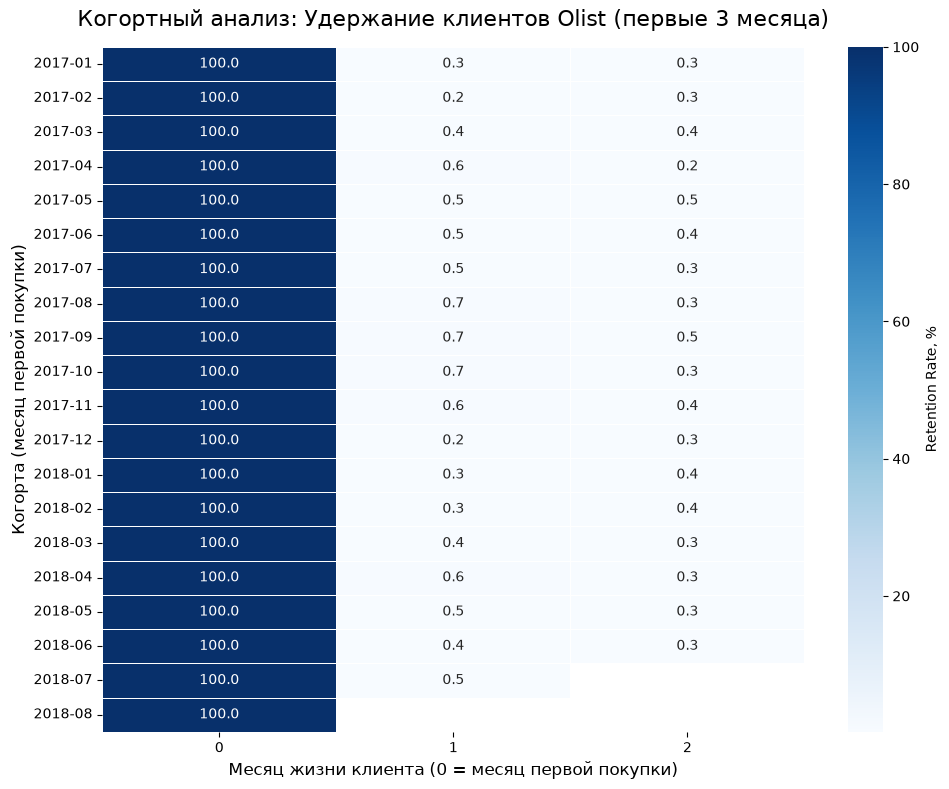

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import os


os.makedirs('../output/figures', exist_ok=True)

# Оставляем ТОЛЬКО первые 3 месяца (0, 1, 2), чтобы график был крупным и читаемым
cohort_plot = cohort_pivot.iloc[:, :3]

plt.figure(figsize=(10, 8)) # Увеличили размер


sns.heatmap(
    cohort_plot, 
    annot=True, 
    fmt='.1f', 
    cmap='Blues', 
    cbar_kws={'label': 'Retention Rate, %'},
    linewidths=.5 
)

plt.title('Когортный анализ: Удержание клиентов Olist (первые 3 месяца)', fontsize=16, pad=15)
plt.xlabel('Месяц жизни клиента (0 = месяц первой покупки)', fontsize=12)
plt.ylabel('Когорта (месяц первой покупки)', fontsize=12)

plt.tight_layout()

# Сохраняем картинку для GitHub
plt.savefig('../output/figures/cohort_heatmap.png', dpi=300)
plt.show()

In [3]:
# Проверяем удержание по КВАРТАЛАМ (чтобы исключить эффект короткого месяца)
cohort_q_query = """
WITH first_orders AS (
    SELECT c.customer_unique_id, MIN(DATE_TRUNC('quarter', o.order_purchase_timestamp)) AS cohort_q
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY 1
),
customer_orders AS (
    SELECT c.customer_unique_id, DATE_TRUNC('quarter', o.order_purchase_timestamp) AS order_q
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY 1, 2
),
cohort_data AS (
    SELECT fo.cohort_q, co.order_q, DATE_DIFF('quarter', fo.cohort_q, co.order_q) AS q_number,
           COUNT(DISTINCT fo.customer_unique_id) AS customers
    FROM first_orders fo
    JOIN customer_orders co ON fo.customer_unique_id = co.customer_unique_id
    GROUP BY 1, 2, 3
),
cohort_sizes AS (
    SELECT cohort_q, COUNT(DISTINCT customer_unique_id) AS total_customers
    FROM first_orders GROUP BY 1
)
SELECT cd.cohort_q, cd.q_number, ROUND((cd.customers * 100.0) / cs.total_customers, 1) AS retention_rate
FROM cohort_data cd
JOIN cohort_sizes cs ON cd.cohort_q = cs.cohort_q
WHERE cd.cohort_q >= '2017-01-01'
ORDER BY 1, 2
"""

cohort_q_df = con.execute(cohort_q_query).df()
cohort_q_pivot = cohort_q_df.pivot(index='cohort_q', columns='q_number', values='retention_rate')
cohort_q_pivot.index = cohort_q_pivot.index.map(lambda p: f"{p.year}-Q{p.quarter}")

display(cohort_q_pivot.iloc[:, :4])

q_number,0,1,2,3
cohort_q,,,,
2017-Q1,100.0,1.0,0.6,0.6
2017-Q2,100.0,1.0,0.9,0.6
2017-Q3,100.0,1.0,0.8,0.7
2017-Q4,100.0,0.7,0.6,0.2
2018-Q1,100.0,0.9,0.3,NaN
2018-Q2,100.0,0.5,NaN,NaN
2018-Q3,100.0,NaN,NaN,NaN


### Выводы по когортному анализу

- В доступном периоде наблюдения доля повторных покупок по когортам низкая: в первые месяцы после первой покупки она составляет менее 1%.
- Этот результат нельзя интерпретировать как доказательство отсутствия программы лояльности или как прямую причину оттока: на него влияют длина окна наблюдения, состав товарных категорий и особенности покупательского поведения.
- Следующая гипотеза: запустить post-purchase коммуникацию с персональным предложением и проверить на A/B-тесте, растёт ли повторная покупка в течение 30–90 дней.
